# Gaussian Mixture Model — Clustering (improving on K-Means)
**Author:** Almeida K.K.O. (IT25103191) &nbsp;|&nbsp; **Group ID:** 2026-Y2-S1-MLB-B11G2-05
**Model type:** Clustering (unsupervised) &nbsp;|&nbsp; **Dataset:** UCI Letter Recognition (group-processed)

## 1. Model Suitability

K-Means describes every cluster with **one centre point** and nothing else. It measures plain
straight-line distance, so it quietly assumes every cluster is a round ball of about the same size,
and that all 21 features matter equally and are unrelated to each other.

A GMM describes every cluster as a **Gaussian "cloud"** with three things:

- a **centre** (the mean), as in K-Means;
- a **shape** (the covariance): the cloud can be stretched or tilted, so it can follow features that
  rise and fall together;
- a **weight**: how big a share of the data the cluster holds, so clusters can have different sizes.

It also gives every row a **probability** of belonging to each cluster instead of one hard answer.

Why this suits our data: many of the 21 features are strongly related (for example `width`, `high`
and `box_area` all describe the size of the letter's box). K-Means counts that same "size"
information several times. A GMM can learn these relationships and stop double-counting them.

The question is the same as in the K-Means notebook: **with the labels hidden, how much of the
letter structure can be found?** The new question is whether flexible cluster shapes find more of it
than round ones.

In [1]:
from sklearn.model_selection import train_test_split
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (adjusted_rand_score, normalized_mutual_info_score,
                             silhouette_score, confusion_matrix)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import json
import warnings
warnings.filterwarnings('ignore')

RANDOM_STATE = 42
sns.set_style('whitegrid')

df = pd.read_csv('../data/external/processed_letter_recognition.csv')
FEATURE_COLS = [c for c in df.columns if c not in ('lettr', 'lettr_encoded')]
LETTER_NAMES = sorted(df['lettr'].unique())

X = df[FEATURE_COLS].values
y = df['lettr_encoded'].values
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print(f"Dataset: {df.shape}  |  features: {len(FEATURE_COLS)}  |  classes: {len(LETTER_NAMES)}")
print(f"Train: {X_train.shape}   Test: {X_test.shape}")

# Same data and same 80/20 split as every other model in the group
X_all, y_all = X, y

Dataset: (18668, 23)  |  features: 21  |  classes: 26
Train: (14934, 21)   Test: (3734, 21)


## 2. Implementation Details

- **Estimator:** `sklearn.mixture.GaussianMixture`. It starts from a K-Means solution
  (`init_params='kmeans'`, the default) and then improves it with the EM algorithm: *(E)* work out
  each row's probability of belonging to each cluster, *(M)* update every cluster's centre, shape and
  weight from those probabilities, and repeat until nothing changes.
- **Hyperparameters tuned:**
  - `covariance_type` — how much freedom the cluster shape has (four choices, explained in Section 3);
  - `reg_covar` — a small amount added to every cluster's variance so no cluster can become
    perfectly flat;
  - `n_components` — the number of clusters.
- **Fixed settings:** `random_state=42` for repeatable results, and `max_iter=300` so EM has time to
  finish. `n_init` stays at its default of 1, because one GMM fit is much slower than one K-Means
  fit. The effect of the random start is measured with five seeds in Section 4 instead.
- **Baseline:** K-Means with exactly the settings of my K-Means notebook (`k=26`, `n_init=10`,
  `random_state=42`), refitted here so both models are scored in the same way.

**How the labels are used.** The model never sees a label: every `fit` call receives only `X`.
Labels are used afterwards in two separate places:

1. on the **training rows**, to choose between settings;
2. on the **test rows**, to report the final score. These rows are not used for fitting or for
   choosing, so the final score is an honest one.

### Why a GMM needs care on this dataset

A GMM has to measure the *spread* of every cluster in every direction. Two properties of our data
make some spreads exactly zero, which is checked below.

In [2]:
ENGINEERED = ['box_area', 'aspect_ratio', 'pixel_density', 'edge_ratio', 'total_variance']
ORIGINAL = [c for c in FEATURE_COLS if c not in ENGINEERED]

n_values = df[ORIGINAL].nunique()
print(f"Different values taken by each of the {len(ORIGINAL)} original features: "
      f"{n_values.min()} to {n_values.max()}")
print(f"Independent columns among the {X_all.shape[1]} features: {np.linalg.matrix_rank(X_all)}")

Different values taken by each of the 16 original features: 6 to 16
Independent columns among the 21 features: 20


**Reading this output:**

- The 16 original features are **whole numbers**, so each one takes only a handful of different
  values. Inside a small cluster, a feature can have the *same* value on every row, which is a
  spread of exactly zero.
- Only 20 of the 21 columns are independent, because Stage 3 built `total_variance` as
  `x2bar + y2bar`. That is an exact copy of information already in the data.

A Gaussian with zero spread in some direction is infinitely thin, and the model's fit score
(likelihood) shoots up for the wrong reason. `reg_covar` is the guard against this, which is why it
is tuned carefully in Section 3 instead of being left at its tiny default of `1e-6`.

The K-Means baseline is fitted first, on the training rows.

In [3]:
def agreement(y_true, clusters):
    # ARI and NMI between a clustering and the true letters (labels are used for checking only)
    return (adjusted_rand_score(y_true, clusters),
            normalized_mutual_info_score(y_true, clusters))

kmeans_train = KMeans(n_clusters=26, n_init=10, random_state=RANDOM_STATE).fit(X_train)
km_train_ari, km_train_nmi = agreement(y_train, kmeans_train.labels_)
print(f"K-Means baseline (k=26, training rows): ARI={km_train_ari:.4f}, NMI={km_train_nmi:.4f}")

K-Means baseline (k=26, training rows): ARI=0.1431, NMI=0.3464


## 3. Parameter Tuning — Varieties Trained

### 3.1 Cluster shape (`covariance_type`) and minimum spread (`reg_covar`)

Four shape varieties are trained, from most to least flexible:

| `covariance_type` | What each cluster is allowed to look like |
|---|---|
| `full` | its own stretched and tilted shape |
| `tied` | stretched and tilted, but **all clusters share one shape** |
| `diag` | its own stretch along each feature, but no tilt (features treated as unrelated) |
| `spherical` | a round ball with its own size (the closest to K-Means) |

Each one is trained with five values of `reg_covar`, from the default `1e-6` up to `1`. That is 20
models, all with 26 components and all fitted on the training rows.

In [4]:
cov_types = ['full', 'tied', 'diag', 'spherical']
reg_values = [1e-6, 1e-3, 1e-2, 1e-1, 1.0]

grid = []
for cov in cov_types:
    for reg in reg_values:
        gmm = GaussianMixture(n_components=26, covariance_type=cov, reg_covar=reg,
                              max_iter=300, random_state=RANDOM_STATE).fit(X_train)
        ari, nmi = agreement(y_train, gmm.predict(X_train))
        grid.append({'covariance_type': cov, 'reg_covar': reg, 'ARI_train': ari, 'NMI_train': nmi,
                     'BIC': gmm.bic(X_train), 'converged': gmm.converged_})
        print(f"{cov:>9} | reg_covar={reg:<6g} | ARI={ari:.4f} | NMI={nmi:.4f} | "
              f"BIC={gmm.bic(X_train):>9.0f} | converged={gmm.converged_}")

grid_df = pd.DataFrame(grid)
best = grid_df.loc[grid_df['ARI_train'].idxmax()]
BEST_COV, BEST_REG = best['covariance_type'], float(best['reg_covar'])
print(f"\nBest variety on the training rows: covariance_type='{BEST_COV}', reg_covar={BEST_REG:g} "
      f"(ARI={best['ARI_train']:.4f}, NMI={best['NMI_train']:.4f})")
print(f"K-Means baseline on the same rows:  ARI={km_train_ari:.4f}, NMI={km_train_nmi:.4f}")

     full | reg_covar=1e-06  | ARI=0.0999 | NMI=0.3425 | BIC=    46210 | converged=True
     full | reg_covar=0.001  | ARI=0.1459 | NMI=0.4037 | BIC=   229050 | converged=True
     full | reg_covar=0.01   | ARI=0.1760 | NMI=0.4296 | BIC=   321345 | converged=True
     full | reg_covar=0.1    | ARI=0.2184 | NMI=0.4801 | BIC=   500406 | converged=True
     full | reg_covar=1      | ARI=0.0984 | NMI=0.3175 | BIC=   891402 | converged=True
     tied | reg_covar=1e-06  | ARI=0.1572 | NMI=0.3859 | BIC=   347982 | converged=True
     tied | reg_covar=0.001  | ARI=0.1556 | NMI=0.3859 | BIC=   451326 | converged=True
     tied | reg_covar=0.01   | ARI=0.1751 | NMI=0.4113 | BIC=   489555 | converged=True
     tied | reg_covar=0.1    | ARI=0.1782 | NMI=0.4364 | BIC=   571143 | converged=True
     tied | reg_covar=1      | ARI=0.0314 | NMI=0.2872 | BIC=   854011 | converged=True
     diag | reg_covar=1e-06  | ARI=0.1314 | NMI=0.3548 | BIC=   578555 | converged=True
     diag | reg_covar=0.001  | A

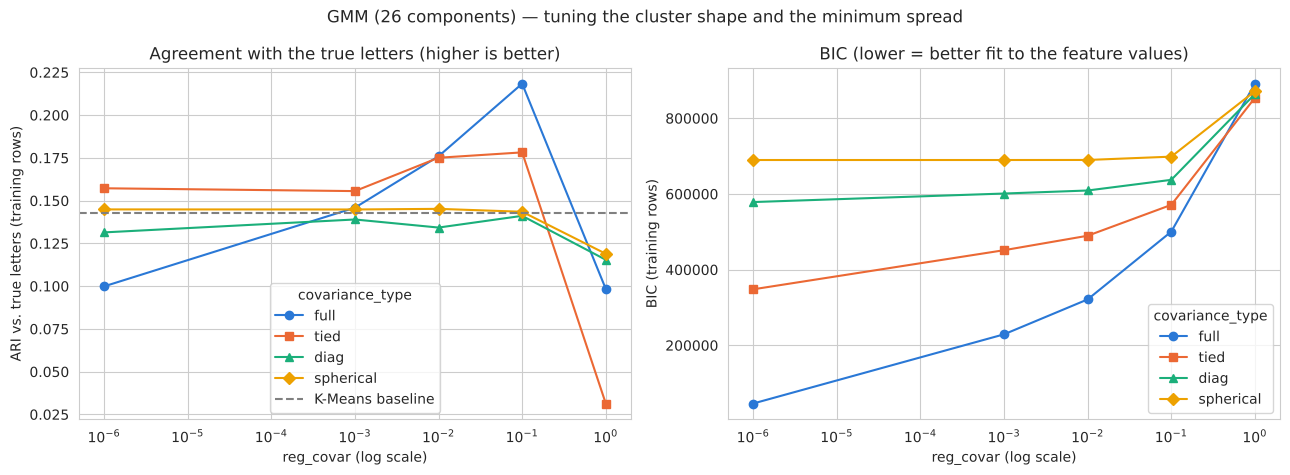

In [5]:
# One colour AND one marker per variety, so the lines can be told apart without relying on colour
STYLES = {'full': ('#2a78d6', 'o'), 'tied': ('#eb6834', 's'),
          'diag': ('#1baf7a', '^'), 'spherical': ('#eda100', 'D')}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for cov in cov_types:
    part = grid_df[grid_df['covariance_type'] == cov]
    color, marker = STYLES[cov]
    axes[0].plot(part['reg_covar'], part['ARI_train'], marker=marker, color=color, label=cov)
    axes[1].plot(part['reg_covar'], part['BIC'], marker=marker, color=color, label=cov)
axes[0].axhline(km_train_ari, color='grey', linestyle='--', label='K-Means baseline')
axes[0].set_ylabel('ARI vs. true letters (training rows)')
axes[0].set_title('Agreement with the true letters (higher is better)')
axes[1].set_ylabel('BIC (training rows)')
axes[1].set_title('BIC (lower = better fit to the feature values)')
for ax in axes:
    ax.set_xscale('log')
    ax.set_xlabel('reg_covar (log scale)')
    ax.legend(title='covariance_type')
plt.suptitle('GMM (26 components) — tuning the cluster shape and the minimum spread')
plt.tight_layout()
plt.savefig('../results/eda_visualizations/almeida_gmm_tuning.png', dpi=110, bbox_inches='tight')
plt.show()

**Reading the results:**

- **The default GMM is worse than K-Means.** `full` with the default `reg_covar=1e-6` scores an ARI
  of 0.10, below the K-Means baseline of 0.14 (the dashed line). Its clusters become thin and flat,
  for the reasons shown in Section 2.
- **`reg_covar` fixes this.** As it is raised, `full` climbs to an ARI of 0.22 at `reg_covar=0.1`.
  At `reg_covar=1` every variety drops, because that much added spread blurs the clusters into
  each other.
- **`spherical` sits on the K-Means line** (ARI about 0.145). Round clusters are the K-Means
  assumption, so this is expected. It shows the gain does not come from using a GMM as such.
- **`diag` is no better than K-Means.** It lets clusters stretch, but still treats the features as
  unrelated, and ours are strongly related.
- **`tied` and `full` are the only varieties that beat K-Means.** They are the two that can model
  related features. `full` is best because each cluster gets its own shape.
- **BIC cannot choose `reg_covar` on this data (right plot).** BIC keeps improving as `reg_covar`
  shrinks, and its favourite is `full` with `1e-6`, the same model that falls below K-Means on the
  left. BIC measures how well the model fits the *feature values*, not how well the clusters match
  the letters, and thin flat clusters fit whole-number features extremely well.

**Chosen variety:** `covariance_type='full'` with `reg_covar=0.1`, picked by ARI on the training
rows. The features are standardised (each has a variance of 1), so `reg_covar=0.1` means every
cluster keeps a spread of at least √0.1 ≈ 0.32 standard deviations in every direction.

### 3.2 Number of components

The chosen variety is now trained with different numbers of components. The **BIC** (Bayesian
Information Criterion) is the standard label-free way to pick this number for a GMM: it rewards a
good fit and charges a penalty for every extra parameter, and **lower is better**. With `reg_covar`
held at one sensible value, BIC values can be compared fairly with each other.

In [6]:
k_values = [8, 12, 16, 20, 26, 32, 40]

sweep = []
for k in k_values:
    gmm = GaussianMixture(n_components=k, covariance_type=BEST_COV, reg_covar=BEST_REG,
                          max_iter=300, random_state=RANDOM_STATE).fit(X_train)
    ari, nmi = agreement(y_train, gmm.predict(X_train))
    sweep.append({'k': k, 'BIC': gmm.bic(X_train), 'ARI_train': ari, 'NMI_train': nmi})
    print(f"k={k:>3} | BIC={gmm.bic(X_train):>9.0f} | ARI={ari:.4f} | NMI={nmi:.4f}")

sweep_df = pd.DataFrame(sweep)
k_bic = int(sweep_df.loc[sweep_df['BIC'].idxmin(), 'k'])
bic_at_26 = float(sweep_df.loc[sweep_df['k'] == 26, 'BIC'].iloc[0])
print(f"\nk preferred by BIC: {k_bic} (BIC={sweep_df['BIC'].min():.0f});  BIC at k=26: {bic_at_26:.0f}")

k=  8 | BIC=   530169 | ARI=0.0926 | NMI=0.2938
k= 12 | BIC=   515643 | ARI=0.1195 | NMI=0.3400
k= 16 | BIC=   505856 | ARI=0.1683 | NMI=0.4123
k= 20 | BIC=   498827 | ARI=0.1950 | NMI=0.4567
k= 26 | BIC=   500406 | ARI=0.2184 | NMI=0.4801
k= 32 | BIC=   501650 | ARI=0.2241 | NMI=0.4845
k= 40 | BIC=   505549 | ARI=0.2302 | NMI=0.5014

k preferred by BIC: 20 (BIC=498827);  BIC at k=26: 500406


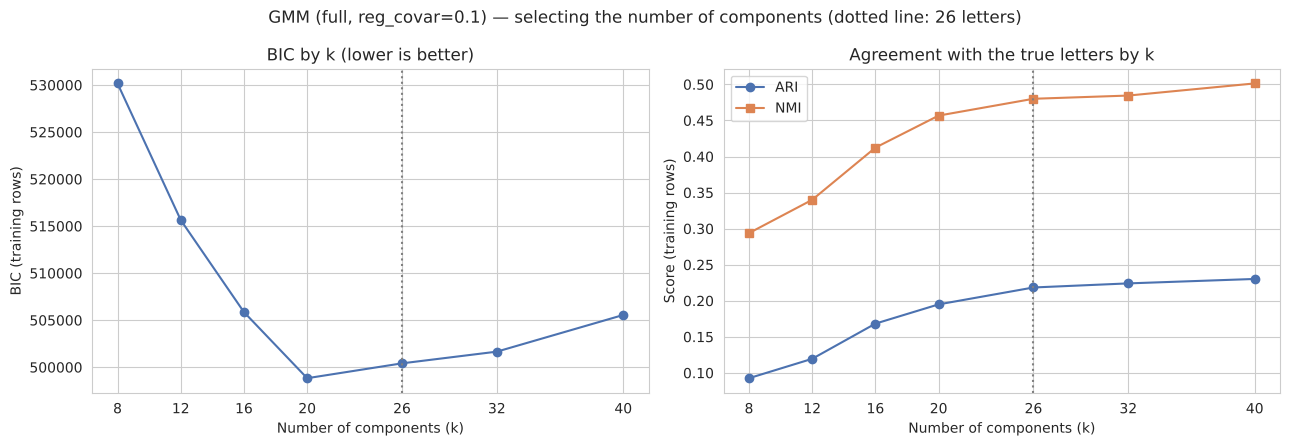

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(sweep_df['k'], sweep_df['BIC'], marker='o', color='#4C72B0')
axes[0].set_xlabel('Number of components (k)'); axes[0].set_ylabel('BIC (training rows)')
axes[0].set_title('BIC by k (lower is better)')
axes[1].plot(sweep_df['k'], sweep_df['ARI_train'], marker='o', color='#4C72B0', label='ARI')
axes[1].plot(sweep_df['k'], sweep_df['NMI_train'], marker='s', color='#DD8452', label='NMI')
axes[1].set_xlabel('Number of components (k)'); axes[1].set_ylabel('Score (training rows)')
axes[1].set_title('Agreement with the true letters by k')
axes[1].legend()
for ax in axes:
    ax.axvline(26, color='grey', linestyle=':')
    ax.set_xticks(k_values)
plt.suptitle(f"GMM ({BEST_COV}, reg_covar={BEST_REG:g}) — selecting the number of components "
             f"(dotted line: 26 letters)")
plt.tight_layout()
plt.savefig('../results/eda_visualizations/almeida_gmm_k_selection.png', dpi=110, bbox_inches='tight')
plt.show()

**Reading the results:**

- **BIC is lowest at `k=20` and almost the same at `k=26`** (498,827 against 500,406, a difference
  of about 0.3%). Beyond 26 it rises steadily. So with no labels at all, BIC points to roughly 20 to
  26 clusters. That is close to the true number of letters, and `k=20` is also the value the
  silhouette score preferred in the K-Means notebook.
- **ARI and NMI rise quickly up to 26 and then flatten.** They still creep upwards with more
  clusters. NMI in particular tends to grow as clusters are added, so two models should only be
  compared at the same `k`.

**Chosen number of components: 26.** It lies inside BIC's best region, it matches the number of
letters, and it is the same `k` as the final K-Means model, so the two can be compared like for like.

## 4. Evaluation

**Metrics** (the same ones as the K-Means notebook, so the two models can be compared directly):

- **Adjusted Rand Index** (external): agreement between the clusters and the true letters. Random
  assignment scores 0 and a perfect match scores 1.
- **Normalized Mutual Information** (external): how much knowing the cluster tells you about the
  true letter, from 0 to 1.
- **Silhouette score** (internal): how tight and well separated the clusters are, using no labels.
- **BIC** (internal, GMM only): used above to choose the number of components.

Accuracy is still not used, because a cluster ID is not a letter.

**Validation method:**

1. **Held-out test rows.** Both models are fitted on the 14,934 training rows and scored on the 3,734
   test rows, which played no part in fitting or in choosing the settings.
2. **Five random seeds.** Both K-Means and GMM start from random positions, so one run can be lucky
   or unlucky. Each model is run with five different seeds and the average is reported.

In [8]:
SEEDS = [42, 0, 1, 2, 3]

rows = []
for seed in SEEDS:
    km = KMeans(n_clusters=26, n_init=10, random_state=seed).fit(X_train)
    gmm = GaussianMixture(n_components=26, covariance_type=BEST_COV, reg_covar=BEST_REG,
                          max_iter=300, random_state=seed).fit(X_train)
    km_ari, km_nmi = agreement(y_test, km.predict(X_test))
    gmm_ari, gmm_nmi = agreement(y_test, gmm.predict(X_test))
    rows.append({'seed': seed, 'KMeans_ARI': km_ari, 'GMM_ARI': gmm_ari,
                 'KMeans_NMI': km_nmi, 'GMM_NMI': gmm_nmi})

test_df = pd.DataFrame(rows)
print("Scores on the held-out TEST rows (models fitted on the training rows only)\n")
print(test_df.round(4).to_string(index=False))

score_cols = ['KMeans_ARI', 'GMM_ARI', 'KMeans_NMI', 'GMM_NMI']
test_mean, test_std = test_df[score_cols].mean(), test_df[score_cols].std()
print()
for c in score_cols:
    print(f"{c:>11}: mean={test_mean[c]:.4f}  std={test_std[c]:.4f}  "
          f"min={test_df[c].min():.4f}  max={test_df[c].max():.4f}")
print(f"\nGMM beats K-Means on ARI in {(test_df['GMM_ARI'] > test_df['KMeans_ARI']).sum()} of "
      f"{len(SEEDS)} seeds, and on NMI in {(test_df['GMM_NMI'] > test_df['KMeans_NMI']).sum()} of {len(SEEDS)}.")

Scores on the held-out TEST rows (models fitted on the training rows only)

 seed  KMeans_ARI  GMM_ARI  KMeans_NMI  GMM_NMI
   42      0.1343   0.2067      0.3498   0.4782
    0      0.1565   0.2173      0.3757   0.4755
    1      0.1462   0.1828      0.3660   0.4488
    2      0.1356   0.2148      0.3554   0.4838
    3      0.1354   0.2019      0.3609   0.4627

 KMeans_ARI: mean=0.1416  std=0.0096  min=0.1343  max=0.1565
    GMM_ARI: mean=0.2047  std=0.0137  min=0.1828  max=0.2173
 KMeans_NMI: mean=0.3616  std=0.0099  min=0.3498  max=0.3757
    GMM_NMI: mean=0.4698  std=0.0140  min=0.4488  max=0.4838

GMM beats K-Means on ARI in 5 of 5 seeds, and on NMI in 5 of 5.


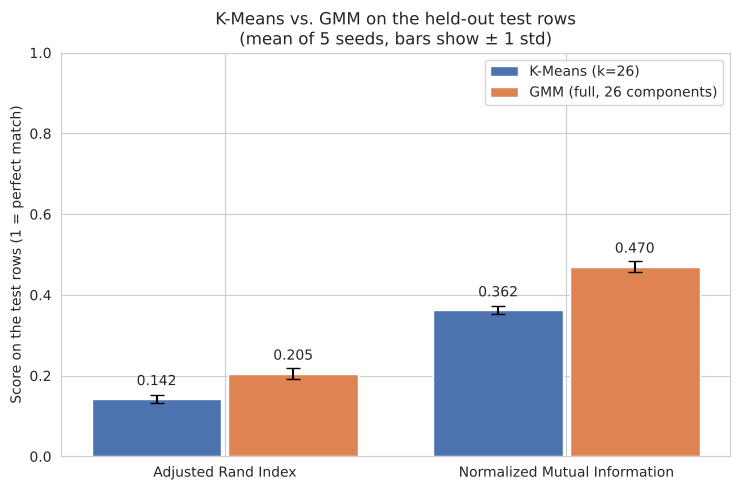

In [9]:
fig, ax = plt.subplots(figsize=(7.5, 5))
x = np.arange(2)
bars_km = ax.bar(x - 0.2, [test_mean['KMeans_ARI'], test_mean['KMeans_NMI']], 0.38,
                 yerr=[test_std['KMeans_ARI'], test_std['KMeans_NMI']], capsize=5,
                 color='#4C72B0', label='K-Means (k=26)')
bars_gmm = ax.bar(x + 0.2, [test_mean['GMM_ARI'], test_mean['GMM_NMI']], 0.38,
                  yerr=[test_std['GMM_ARI'], test_std['GMM_NMI']], capsize=5,
                  color='#DD8452', label=f"GMM ({BEST_COV}, 26 components)")
for bars in (bars_km, bars_gmm):
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.035,
                f"{bar.get_height():.3f}", ha='center')
ax.set_xticks(x); ax.set_xticklabels(['Adjusted Rand Index', 'Normalized Mutual Information'])
ax.set_ylim(0, 1); ax.set_ylabel('Score on the test rows (1 = perfect match)')
ax.set_title(f"K-Means vs. GMM on the held-out test rows\n(mean of {len(SEEDS)} seeds, bars show ± 1 std)")
ax.legend()
plt.tight_layout()
plt.savefig('../results/eda_visualizations/almeida_gmm_vs_kmeans.png', dpi=110, bbox_inches='tight')
plt.show()

**Reading the results:** on rows that neither model saw, the GMM scores higher than K-Means with
every one of the five seeds, on both metrics. On average the ARI rises from 0.142 to 0.205 and the
NMI from 0.362 to 0.470. The gap between the models is several times larger than the seed-to-seed
variation (the error bars), so it is not a lucky run.

**Same protocol as the K-Means notebook.** To put the GMM next to the K-Means numbers already in
the group report, both models are also fitted on **all 18,668 rows** with `random_state=42`, exactly
as the K-Means notebook did. The silhouette score uses the same 5,000-row sample as that notebook.

In [10]:
kmeans_all = KMeans(n_clusters=26, n_init=10, random_state=RANDOM_STATE).fit(X_all)
gmm_all = GaussianMixture(n_components=26, covariance_type=BEST_COV, reg_covar=BEST_REG,
                          max_iter=300, random_state=RANDOM_STATE).fit(X_all)
km_clusters = kmeans_all.labels_
gmm_clusters = gmm_all.predict(X_all)

km_all_ari, km_all_nmi = agreement(y_all, km_clusters)
gmm_all_ari, gmm_all_nmi = agreement(y_all, gmm_clusters)

sample_idx = np.random.RandomState(RANDOM_STATE).choice(len(X_all), 5000, replace=False)
km_sil = silhouette_score(X_all[sample_idx], km_clusters[sample_idx])
gmm_sil = silhouette_score(X_all[sample_idx], gmm_clusters[sample_idx])

# Soft assignment: the GMM gives every row a probability for each of the 26 clusters
proba = gmm_all.predict_proba(X_all)
top_proba = proba.max(axis=1)

print(f"{'All 18,668 rows':<28}{'K-Means':>10}{'GMM':>10}")
print(f"{'ARI vs true letters':<28}{km_all_ari:>10.4f}{gmm_all_ari:>10.4f}")
print(f"{'NMI vs true letters':<28}{km_all_nmi:>10.4f}{gmm_all_nmi:>10.4f}")
print(f"{'Silhouette (5,000 sample)':<28}{km_sil:>10.4f}{gmm_sil:>10.4f}")
print(f"\nGMM converged: {gmm_all.converged_} after {gmm_all.n_iter_} EM iterations")
print(f"GMM soft assignment: average top probability = {top_proba.mean():.3f}; "
      f"{(top_proba > 0.9).mean() * 100:.1f}% of rows have a top probability above 0.9")

gmm_metrics = {
    'n_components_chosen': 26,
    'covariance_type': BEST_COV,
    'reg_covar': BEST_REG,
    'ari_vs_true_letters': float(gmm_all_ari),
    'nmi_vs_true_letters': float(gmm_all_nmi),
    'silhouette_5000_sample': float(gmm_sil),
    'bic_preferred_k': k_bic,
    'ari_test_mean_5_seeds': float(test_mean['GMM_ARI']),
    'ari_test_std_5_seeds': float(test_std['GMM_ARI']),
    'nmi_test_mean_5_seeds': float(test_mean['GMM_NMI']),
    'nmi_test_std_5_seeds': float(test_std['GMM_NMI']),
    'kmeans_ari_vs_true_letters': float(km_all_ari),
    'kmeans_nmi_vs_true_letters': float(km_all_nmi),
    'kmeans_silhouette_5000_sample': float(km_sil),
    'kmeans_ari_test_mean_5_seeds': float(test_mean['KMeans_ARI']),
    'kmeans_nmi_test_mean_5_seeds': float(test_mean['KMeans_NMI']),
}

All 18,668 rows                K-Means       GMM
ARI vs true letters             0.1507    0.1894
NMI vs true letters             0.3638    0.4578
Silhouette (5,000 sample)       0.1390    0.0980

GMM converged: True after 31 EM iterations
GMM soft assignment: average top probability = 0.954; 86.3% of rows have a top probability above 0.9


**Reading the results:**

- **K-Means column:** the ARI of 0.1507 and NMI of 0.3638 are exactly the values saved by the
  K-Means notebook, which confirms the baseline here is the same model.
- **ARI and NMI:** the GMM is higher on both (0.189 against 0.151, and 0.458 against 0.364). This is
  one run from one random start, so it should be read together with the five-seed results above.
- **Silhouette:** the GMM is *lower* (0.098 against 0.139). Silhouette uses straight-line distance
  and rewards tight, round clusters, which is exactly what K-Means builds. The GMM's stretched
  clusters look less tidy by this measure even though they match the letters better.
- **Soft assignment:** the average top probability is 0.95, so the GMM is usually sure which of
  *its own clusters* a row belongs to. This is confidence about clusters, not about letters.

The two heatmaps below show where the rows of each letter end up.

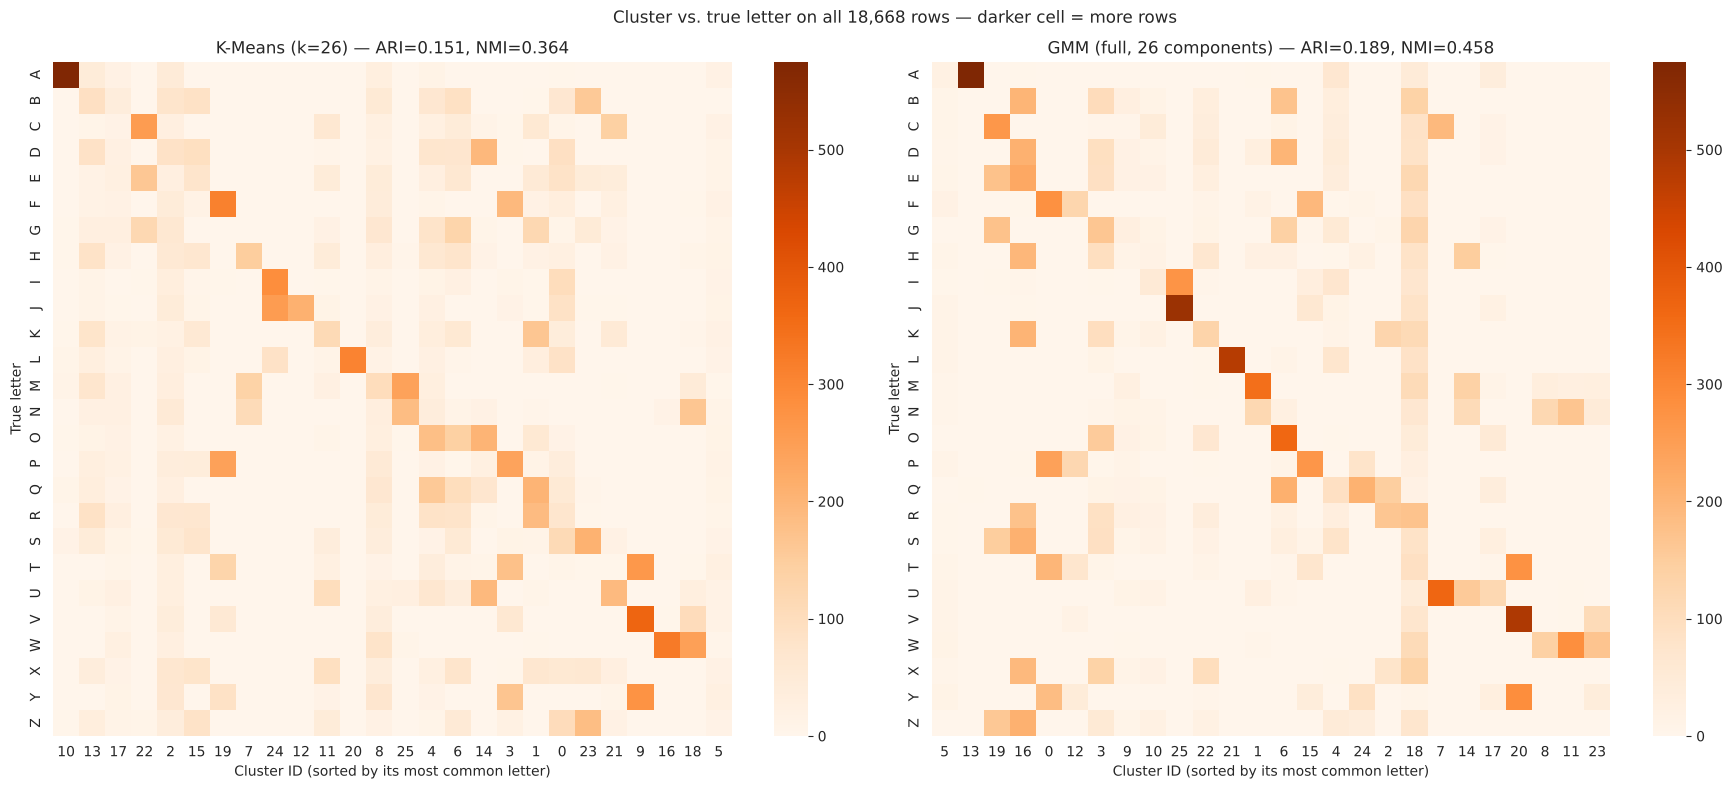

Letters with more than half of their rows in ONE cluster:
  K-Means: A I V
  GMM:     A I J L O V


In [11]:
def letter_table(clusters):
    # Rows = true letters, columns = cluster IDs. The columns are then sorted so that each
    # cluster sits next to the letter it holds most of, which makes the picture easier to read.
    table = confusion_matrix(y_all, clusters)
    order = np.argsort(table.argmax(axis=0), kind='stable')
    return table[:, order], order

km_table, km_order = letter_table(km_clusters)
gmm_table, gmm_order = letter_table(gmm_clusters)
vmax = max(km_table.max(), gmm_table.max())      # one shared colour scale for a fair comparison

fig, axes = plt.subplots(1, 2, figsize=(18, 8))
panels = [(km_table, km_order, f"K-Means (k=26) — ARI={km_all_ari:.3f}, NMI={km_all_nmi:.3f}"),
          (gmm_table, gmm_order, f"GMM ({BEST_COV}, 26 components) — ARI={gmm_all_ari:.3f}, NMI={gmm_all_nmi:.3f}")]
for ax, (table, order, title) in zip(axes, panels):
    sns.heatmap(table, yticklabels=LETTER_NAMES, xticklabels=order, cmap='Oranges',
                vmin=0, vmax=vmax, ax=ax)
    ax.set_xlabel('Cluster ID (sorted by its most common letter)'); ax.set_ylabel('True letter')
    ax.set_title(title)
plt.suptitle('Cluster vs. true letter on all 18,668 rows — darker cell = more rows')
plt.tight_layout()
plt.savefig('../results/eda_visualizations/almeida_gmm_clusters_vs_truth.png', dpi=110, bbox_inches='tight')
plt.show()

# For each letter: the largest share of its rows that ends up in a single cluster
km_share = km_table.max(axis=1) / km_table.sum(axis=1)
gmm_share = gmm_table.max(axis=1) / gmm_table.sum(axis=1)
print("Letters with more than half of their rows in ONE cluster:")
print("  K-Means:", ' '.join(l for l, s in zip(LETTER_NAMES, km_share) if s > 0.5))
print("  GMM:    ", ' '.join(l for l, s in zip(LETTER_NAMES, gmm_share) if s > 0.5))

**Reading the heatmaps:** each row is a true letter and each column is a cluster. One dark cell in a
row means that letter sits mostly in one cluster. A dark cell that is alone in its column means that
cluster holds one letter only.

- **The GMM gathers more letters into a single cluster.** Six letters have more than half of their
  rows in one cluster (A, I, J, L, O, V), against three for K-Means (A, I, V). The clearest case is
  L: the GMM puts 71% of all L rows into a cluster that contains nothing else, where K-Means
  manages 46%.
- **Similar shapes still share a cluster in both models:** V with T and Y, I with J, and F with P.
  A flexible cluster shape cannot separate letters whose feature values overlap.
- **The GMM has two very large mixed clusters** (IDs 18 and 16, with about 2,200 and 1,800 rows).
  They collect the hard letters, such as R, X, B, G, E, Z, S and D. So the GMM isolates the
  distinct letters more cleanly, but it does not solve the difficult ones.

## 5. Comparison Across Varieties, Conclusion and Limitations

**Comparison of the GMM varieties:**

- **Cluster shape:** at their best settings the order is `full` (ARI 0.218), `tied` (0.178),
  `spherical` (0.145) and `diag` (0.141), against 0.143 for K-Means on the same training rows. Only
  the two varieties that model related features improve on K-Means.
- **Minimum spread:** `reg_covar` matters more than anything else. For `full`, the ARI moves from
  0.10 to 0.22 and back to 0.10 across the range tested. Leaving it at the default would have made
  the GMM look worse than K-Means.
- **Number of components:** BIC prefers 20 to 26, and 26 is kept.

**GMM against K-Means (both with 26 clusters):**

| Measure | K-Means | GMM |
|---|---|---|
| ARI on test rows, mean of 5 seeds | 0.142 | **0.205** |
| NMI on test rows, mean of 5 seeds | 0.362 | **0.470** |
| ARI on all rows, seed 42 (K-Means notebook protocol) | 0.151 | **0.189** |
| NMI on all rows, seed 42 (K-Means notebook protocol) | 0.364 | **0.458** |
| Silhouette on the 5,000-row sample | **0.139** | 0.098 |

**Conclusion:** the GMM with `covariance_type='full'`, `reg_covar=0.1` and 26 components is selected
as the improved clustering model. On unseen rows it raises the ARI by about 0.06 and the NMI by about
0.11 over K-Means, and it does so with every seed tried. This shows that part of the K-Means
weakness came from its round-cluster assumption, and not only from the missing labels.

The improvement is real but modest. An ARI near 0.2 is still a long way from 1, and similar letters
are still mixed together. The main finding of the K-Means notebook therefore stands: only part of
the letter structure can be found without labels, and the supervised models remain far ahead.

**Limitations / improvements:**

- **Labels helped to choose the settings.** Fitting used no labels, but `covariance_type` and
  `reg_covar` were chosen by ARI on the training rows. With no labels at all this choice would be
  harder, because BIC cannot make it on this data.
- **The result depends on the random start.** The test ARI ranged from 0.183 to 0.217 over five
  seeds. A larger `n_init` would steady it, at the cost of a longer run.
- **The model is much bigger and slower.** A `full` GMM with 26 components and 21 features has 6,577
  parameters, against 546 numbers for the 26 K-Means centres.
- **Gaussians are a rough fit for whole-number features.** This is why `reg_covar` had to be set far
  above its default. Removing the exactly repeated feature (`total_variance`) or reducing the
  features with PCA before clustering are natural next steps.

In [12]:
RESULTS_GMM = {
    'member': 'Almeida K.K.O. (IT25103191)',
    'model_family': 'Gaussian Mixture Model (Clustering)',
    **gmm_metrics,
}
with open('../results/model_metrics/gmm_results.json', 'w') as f:
    json.dump(RESULTS_GMM, f, indent=2, default=str)
print(json.dumps(RESULTS_GMM, indent=2, default=str))

{
  "member": "Almeida K.K.O. (IT25103191)",
  "model_family": "Gaussian Mixture Model (Clustering)",
  "n_components_chosen": 26,
  "covariance_type": "full",
  "reg_covar": 0.1,
  "ari_vs_true_letters": 0.18942476074034684,
  "nmi_vs_true_letters": 0.457759817044727,
  "silhouette_5000_sample": 0.09801769314162936,
  "bic_preferred_k": 20,
  "ari_test_mean_5_seeds": 0.20469644880559704,
  "ari_test_std_5_seeds": 0.013733532403183611,
  "nmi_test_mean_5_seeds": 0.46982473336480357,
  "nmi_test_std_5_seeds": 0.014047680756428465,
  "kmeans_ari_vs_true_letters": 0.1506950817966155,
  "kmeans_nmi_vs_true_letters": 0.3637691561241344,
  "kmeans_silhouette_5000_sample": 0.1390313265994143,
  "kmeans_ari_test_mean_5_seeds": 0.14160934925004298,
  "kmeans_nmi_test_mean_5_seeds": 0.36156193377272855
}
